In [1]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Activate IBM credentials

In [2]:
from qiskit_ibm_provider import IBMProvider

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
provider = IBMProvider(token=IBM_TOKEN, instance="ibm-q-ornl/ornl/phy147")

Get backend and backend configuration

In [3]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = provider.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

# Load custom pulses

In [4]:
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
)
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}

# Get initial calibration with rough amplitude calibration

In [5]:
drive_amp = qk.circuit.Parameter("amp")
drive_amps = np.linspace(0.1, 1.2, 50)

In [6]:
# Create rabi schedule
qubit = 0
gate_key = "x2"
with qk.pulse.build(name=f"{gate_key}_rabi_sched", backend=backend) as rabi_sched:
    signal = pico_gates[gate_key]
    signal_samples = ps.resample(
        duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
    )
    param_gate = ps.scalable_symbolic_pulse(
        duration, signal_samples, gate_key, amp=drive_amp
    )
    qk.pulse.play(param_gate, qk.pulse.DriveChannel(qubit))

# Assign parameters
exp_rabi_scheds = [
    rabi_sched.assign_parameters({drive_amp: a}, inplace=False) for a in drive_amps
]

In [15]:
# Backend
# =====
registers = [0]

# NOTE: If the Rabi rates are True, you have to calibrate!
config_vars = ps.backend_simulation_vars(backend, rabi=True, units=Units)

# Carrier frequencies of each control line
carriers = ps.backend_carriers(backend, config_vars)

# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=config_vars,
    rotating_frame=True,
)

A_decay = functools.partial(
    ps.qubit_decay_model, registers=registers, variables=config_vars
)

H_xtalk = ps.crosstalk_model(registers, ps.backend_edges(backend), config_vars)

# Create a system model
# =====
# Control model
#   Single qubit circuit moment: attach RX models to each qubit
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in range(1):

    # if qubit_index in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)

    # NOTE: doesn't work with quantum channel simulator yet
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel
    As_static += Ajs_static

# Construct solver
solver = qk_d.Solver(
    static_hamiltonian=np.zeros_like(H_xtalk),
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
    dt=dt,
)
psi0 = ps.qiskit_ground_state(len(registers))

# Vmap of the rabi calibrations
solver.model.evaluation_mode = "sparse"
solns = solver.solve(
    t_span=[0.0, duration * dt],
    t_eval=[duration * dt],
    y0=psi0,
    signals=exp_rabi_scheds,
    atol=1e-16,
    rtol=1e-16,
    method="jax_odeint",
)

rabi_data = np.array([np.abs(s.y[-1][1]) ** 2 for s in solns])

/Users/epelaezc/Desktop/Research/pulse-simulator/.venv/lib/python3.11/site-packages/qiskit_dynamics/solvers/solver_classes.py:525: UserWarning: Attempting to internally JAX-compile simulation of schedules, with Solver.model.array_library not in ["numpy", "jax", "jax_sparse"]. If an error is not raised, explicitly set array_library at Solver instantation to one of these options to remove this warning.
  warn(


In [8]:
from scipy.optimize import curve_fit


def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)

    return fitparams, y_fit


# center data around 0
def baseline_remove(values):
    return np.array(values) - np.mean(values)

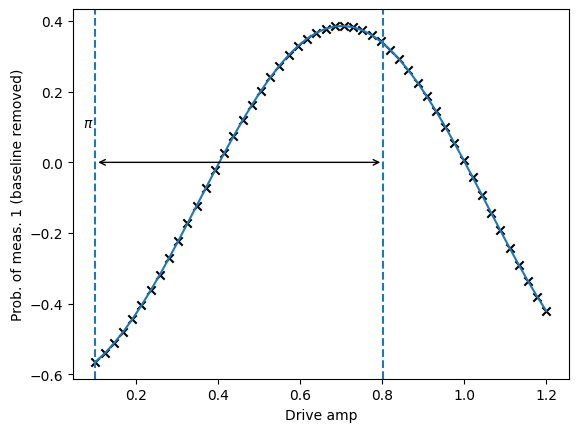

In [9]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(
    drive_amps,
    rabi_values,
    lambda x, A, B, drive_period, phi: (
        A * np.cos(2 * np.pi * x / drive_period - phi) + B
    ),
    [1, 1, 1.3, 0.5],
)

plt.scatter(drive_amps, rabi_values, marker="x", color="black")
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2]  # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period / 2, linestyle="--")
plt.axvline(drive_amps[0], linestyle="--")
plt.annotate(
    "",
    xy=(drive_amps[0], 0),
    xytext=(drive_amps[0] + drive_period / 2, 0),
    arrowprops=dict(arrowstyle="<->"),
)
plt.annotate("$\pi$", xy=(drive_amps[0] - 0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [10]:
drive_period / 2

0.7015862145659074

# Simulate fine amplitude calibration experiments

Tutorial: https://qiskit-extensions.github.io/qiskit-experiments/tutorials/calibrations.html#fine-calibrations-of-a-pulse-amplitude

In [11]:
d0, inst_map = qk.pulse.DriveChannel(0), qk.pulse.InstructionScheduleMap()

In [12]:
# rough_amp = drive_period / 2 # from simulations above
rough_amp = 0.466801855701875  # from hardware calibrations done in notebook 12

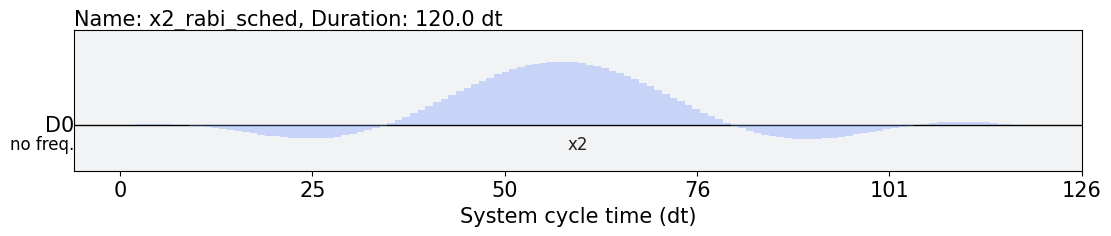

In [13]:
calibrated_sched = rabi_sched.assign_parameters(
    {drive_amp: rough_amp}, inplace=False
)  # from hardware
inst_map.add(
    "x", (0,), calibrated_sched
)  # add calibrated schedule to the instruction map
calibrated_sched.draw()

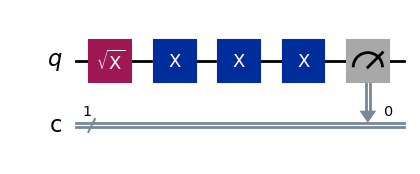

In [14]:
fine_exp = qk_e.library.FineXAmplitude((0,), backend=backend)
fine_exp.set_transpile_options(inst_map=inst_map)
fine_exp.circuits()[4].draw(output="mpl", style="iqp")

In [137]:
exp_job = fine_exp.run(backend)
exp_job

ExperimentData(FineXAmplitude, c0e12cfd-fc60-4eeb-a7a5-4845943f48f4, job_ids=['cqxj8mthepxg00818r7g'], metadata=<4 items>)

In [170]:
exp_job.status()

<ExperimentStatus.DONE: 'experiment jobs and analysis have successfully run'>

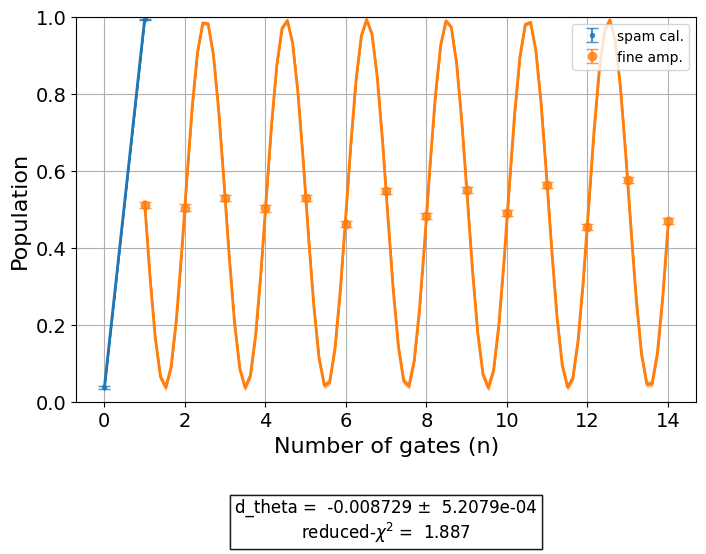

In [171]:
exp_data = exp_job.block_for_results()
exp_data.figure(0)

In [176]:
target_angle = np.pi
dtheta = exp_data.analysis_results("d_theta").value.nominal_value
scale = target_angle / (target_angle + dtheta)

In [177]:
f"Original amplitude {rough_amp}, scaled by {scale} is {rough_amp * scale}"

'Original amplitude 0.466801855701875, scaled by 1.0027864108056215 is 0.46810255743668683'